In [1]:
%load_ext autoreload
%autoreload 2

In [53]:
import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
EPOCHS = 1000
LN10 = np.log(10)

mu, sigma = 0, 10
dim = 100
n_runs = 10
floor = 40 * LN10
rng = np.random.default_rng(seed=42)

utils.set_paper_style()

In [62]:
STYLE = {
    "CCD":   dict(color="#0072B2", ls="-",  lw=1.3),
    "ERate": dict(color="#000000", ls="--", lw=1.0),
    "PRate": dict(color="#D55E00", ls="-",  lw=1.3),
}

In [63]:
A = rng.normal(mu, sigma, (dim, dim))
b = rng.normal(mu, sigma, (dim, 1))

In [67]:
def rate_ccd(A): 
    """
    Compute rate for Cyclic Coordinate Descent (CCD) using the spectral radius.

    params:
        n: dimension
        c: off-diagonal value
    """
    D = np.diag(np.diag(A))
    L = -np.tril(A, -1)
    C = np.linalg.inv(D - L) @ L.T

    return -np.log(np.max(np.abs(np.linalg.eigvals(C))))

def run_ccd(epochs, x0, A, b):
    """
    Run CCD algorithms on general objective Ax - b norm sqaures
    """

    D = np.diag(np.diag(A))
    L = -np.tril(A, -1)
    C = np.linalg.inv(D - L) @ L.T

    x_star = np.linalg.solve(A, b)
    x = (x0  - x_star) / np.linalg.norm(x0 - x_star)
    errors = np.zeros(epochs + 1)

    for epoch in range(epochs):
        x = C @ x # Errors 
        norm = np.linalg.norm(x)
        x /= norm
        errors[epoch + 1] = errors[epoch] + np.log(norm) 

    return errors

def run_prcd(epochs, x0, H, c, n_runs, rng, probs=None):
    """
    Pathwise rate for RCD on f(x) = 0.5 x^T H x - c^T x.
    Per-epoch clock: one epoch = n random coordinate updates.

    params:
        H: Hessian (A_c for the A_c problem; A.T @ A for least squares)
        c: linear term (b for A_c; A.T @ b for least squares)
        probs: sampling distribution (None = uniform, i.e. RCDM(0);
               np.diag(H) / np.trace(H) gives RCDM(1))
    """

    n = H.shape[0]
    d = np.diag(H)
    x_star = np.linalg.solve(H, c)
    errors = np.zeros((n_runs, epochs + 1))

    for row in range(n_runs):
        e = (x0 - x_star) / np.linalg.norm(x0 - x_star)
        for epoch in range(epochs):
            g = H @ e                       # recompute every epoch (see below)
            for i in rng.choice(n, size=n, p=probs):
                delta = -g[i] / d[i]        # exact minimization in coordinate i
                e[i] += delta
                g += delta * H[:, i]        
            norm = np.linalg.norm(e)
            e /= norm
            errors[row, epoch + 1] = errors[row, epoch] + np.log(norm)

    return errors, errors.mean(axis=0), errors.std(axis=0)

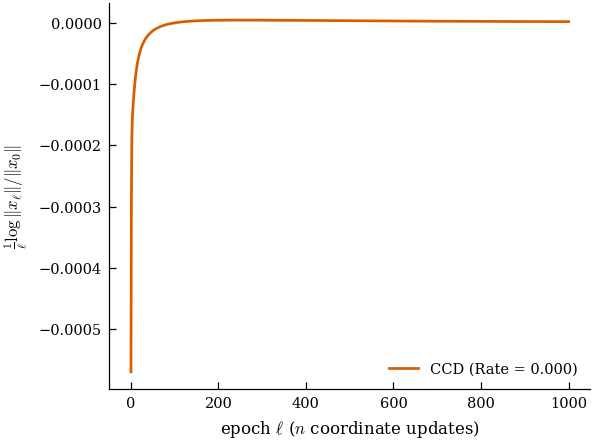

In [68]:
x_coor = np.arange(EPOCHS + 1)
ccd_errors = run_ccd(EPOCHS, np.zeros((dim, 1)), A.T @ A, A.T @ b)
ccd_rate = rate_ccd(A.T @ A)

fig, ax = plt.subplots(figsize=(4, 3))

ax.plot(x_coor[1:], -ccd_errors[1:] / x_coor[1:], **STYLE["PRate"], 
        label=f"CCD (Rate = {ccd_rate:.3f})")


ax.set_xlabel(r"epoch $\ell$ ($n$ coordinate updates)")
ax.set_ylabel(r"$\frac{1}{\ell}\log\|x_\ell\| / \|x_0\|$")
ax.legend(loc="lower right")

In [69]:
def plot_algo(epochs, n, c, x0, n_runs, rng, floor=40 * LN10):
    """
    Plot different algorithms such as CCD, RCD, and ERCD. For RCD, plot both the spread for each path rate and the mean rate for n_runs.
    The plot shows the convergence rate for every algorithms and the error for path rate.

    params:
        epochs: number of epochs
        n: dimension
        c: off-diagonal value
        x0: initial vector
        n_runs: number of runs for path rate
        rng: random number generator from np.random.default_rng(seed)
        floor: threshold to set xlim in the plot (default to 40)

    return:
        fig, ax
    """
    
    ccd_rate = rate_ccd(n, c)
    rcd_erate = erate_rcd(n, c)
    x_coor = np.arange(epochs + 1)

    ccd_errors = run_ccd(epochs, n, c, x0)
    rcd_errors = -rcd_erate * x_coor
    prcd_errors, mean_prcd, std_prcd = run_prcd(epochs, n, c, x0, n_runs, rng)

    half = epochs // 2
    prcd_rates = -(prcd_errors[:, -1] - prcd_errors[:, half]) / (epochs - half)
    prcd_rate = np.mean(prcd_rates)
    prcd_se = prcd_rates.std(ddof=1) / np.sqrt(n_runs)

    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(x_coor, ccd_errors, **STYLE["CCD"], label=f"CCD (Rate = {ccd_rate:.3f})")
    ax.plot(x_coor, rcd_errors, **STYLE["ERate"], label=f"Exact slope (ERate = {rcd_erate:.3f})")

    ax.plot(x_coor, prcd_errors.T, color=STYLE["PRate"]["color"], lw=0.3, alpha=0.3)
    ax.fill_between(x_coor, mean_prcd - std_prcd, mean_prcd + std_prcd, color=STYLE["PRate"]["color"], alpha=0.25, lw=0)
    ax.plot(x_coor, mean_prcd, **STYLE["PRate"], label=f"RCD, mean ± std of {n_runs} runs\n(PRate = {prcd_rate:.3f} ± {prcd_se:.3f})")

    slowest = min(ccd_rate, rcd_erate, prcd_rate)
    ax.set_xlim(0, min(epochs, 1.1 * floor / slowest))
    ax.set_ylim(-floor, 1)
    ax.set_xlabel(r"epoch $\ell$ ($n$ coordinate updates)")
    ax.set_ylabel(r"$\log\|x_\ell\| / \|x_0\|$")
    ax.legend(loc="upper right")
    return fig, ax

In [71]:
x_coor = np.arange(EPOCHS + 1)

ccd_errors = run_ccd(EPOCHS, np.ones((dim, 1)), A, b)
prcd_errors, mean_prcd, std_prcd = run_prcd(EPOCHS, np.zeros((dim, 1)), A.T @ A, A.T @ b, n_runs, rng)
                                            
half = EPOCHS // 2
prcd_rates = -(prcd_errors[:, -1] - prcd_errors[:, half]) / (EPOCHS - half)
prcd_rate = np.mean(prcd_rates)
prcd_se = prcd_rates.std(ddof=1) / np.sqrt(n_runs)
fig, ax = plt.subplots(figsize=(4, 3))

ax.plot(x_coor[1:], -prcd_errors[:, 1:].T/ x_coor[1:].reshape((EPOCHS, -1)), 
        color=STYLE["PRate"]["color"], lw=0.3, alpha=0.3)
ax.fill_between(x_coor[1:], -(mean_prcd[1:] - std_prcd[1:]) / (x_coor[1:]), -(mean_prcd[1:] + std_prcd[1:]) / (x_coor[1:]), 
                color=STYLE["PRate"]["color"], alpha=0.25, lw=0)
ax.plot(x_coor[1:], -mean_prcd[1:] / x_coor[1:], **STYLE["PRate"], 
        label=f"RCD, mean ± std of {n_runs} runs\n(PRate = {prcd_rate:.3f} ± {prcd_se:.3f})")


ax.set_xlabel(r"epoch $\ell$ ($n$ coordinate updates)")
ax.set_ylabel(r"$\frac{1}{\ell}\log\|x_\ell\| / \|x_0\|$")
ax.legend(loc="upper right")

ValueError: non-broadcastable output operand with shape (100,1) doesn't match the broadcast shape (100,100)